In [1]:
# Primeiros passos:

# Importar biblioteca
import pandas as pd

# Carregar dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Mostrar
print("Shape:",df.shape)
print(display(df.head())) # print-display é pra facilitar a cópia das saídas no VSCode

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


None


O que cada coluna representa?

| Variável    | Descrição                                        | Tipo       |
| ----------- | ------------------------------------------------ | ---------- |
| `age`       | Idade do cliente                                 | Numérica   |
| `job`       | Ocupação                                         | Categórica |
| `marital`   | Estado civil                                     | Categórica |
| `education` | Escolaridade                                     | Categórica |
| `default`   | Possui crédito em inadimplência?                 | Categórica |
| `balance`   | Saldo médio anual                                | Numérica   |
| `housing`   | Possui empréstimo imobiliário?                   | Categórica |
| `loan`      | Possui empréstimo pessoal?                       | Categórica |
| `contact`   | Tipo de comunicação utilizada                    | Categórica |
| `day`       | Dia do último contato                            | Numérica   |
| `month`     | Mês do último contato                            | Categórica |
| `duration`  | Duração do último contato, em segundos           | Numérica   |
| `campaign`  | Número de contatos nesta campanha                | Numérica   |
| `pdays`     | Dias desde o último contato em campanha anterior | Numérica   |
| `previous`  | Número de contatos em campanhas anteriores       | Numérica   |
| `poutcome`  | Resultado da campanha anterior                   | Categórica |
| `y`         | O cliente aderiu ao depósito a prazo?            | Alvo       |

### O que estamos tentando prever?
A variável-alvo y indica se o cliente aderiu ou não a um depósito a prazo oferecido pelo banco.

Um depósito a prazo é um produto financeiro no qual o cliente deposita uma quantia no banco por determinado período, normalmente com uma remuneração (juros) previamente estabelecida ou definida por condições contratuais.

É semelhante, em termos gerais, a um CDB no Brasil: o cliente deixa o dinheiro aplicado por um prazo e recebe uma remuneração conforme as condições do produto.

Portanto:
- y = yes: o cliente aceitou a oferta e aderiu ao depósito a prazo.
- y = no: o cliente não aderiu.

In [2]:
# Primeira inspeção dos dados

print("----------------------------------------------------------------------------------------------------------------------------")
print("Info:\n")
df.info()

print("----------------------------------------------------------------------------------------------------------------------------")
print("Describe:\n")
display(df.describe(include="all").T)

print("----------------------------------------------------------------------------------------------------------------------------")
print("Valores ausentes:\n")
print(df.isna().sum())

print("----------------------------------------------------------------------------------------------------------------------------")
print("Distribuição da variável-alvo:\n")
print(df["y"].value_counts(normalize=True) * 100)

----------------------------------------------------------------------------------------------------------------------------
Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


----------------------------------------------------------------------------------------------------------------------------
Valores ausentes:

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
----------------------------------------------------------------------------------------------------------------------------
Distribuição da variável-alvo:

no     88.30152
yes    11.69848
Name: y, dtype: float64


In [3]:
# Relevante: 'unknown' aparece em 36959 dos 45211 dados (82%) em poutcome!

# Isso pode ser problemático porque algo desconhecido não releva padrão nenhum. Pode ser tanto algo bom quanto algo ruim
# Uma das possibilidades de lidar com isso seria excluir dados que contenham essa particularidade.
# Porém, se considerássemos excluir todas as linhas que apresentam pelo menos um unknown, já sabemos 
# que a coluna poutcome nos faria perder 82% do dataset.
# Entáo, talvez seja preciso eliminar essa coluna problemática... Mas antes, vamos ver se essa é uma particularidade dela
# ou se isso também acontece em outras colunas

In [4]:
# Vamos fazer uma inspeção de categorias desconhecidas (unknown)

# Selecionar as variáveis categóricas, excluindo a poutcome, cuja alta quantidade de unknown já foi identificada
categorical_cols = df.select_dtypes(include="object").columns.drop(["poutcome"])
# Desconsiderar dessa contagem porque já sabemos que 82% dela é unknown. Queremos o padrão no restante do dataset

# Contar os valores unknown individualmente em cada variável
unknown_counts = (df[categorical_cols] == "unknown").sum()

# Organizar as quantidades e os respectivos percentuais
unknown_summary = pd.DataFrame({
    "Quantidade": unknown_counts,
    "Percentual (%)": unknown_counts / len(df) * 100
}).sort_values("Quantidade", ascending=False)

print("Distribuição de categorias desconhecidas por variável:\n")
display(unknown_summary)

# Verificar se cada registro possui pelo menos um unknown nas variáveis selecionadas
unknown_rows = (df[categorical_cols] == "unknown").any(axis=1) 
# any(axis=1)  verifica se existe pelo menos um True na linha. 
# O axis=1 indica que a verificação acontece horizontalmente, entre as colunas.

# Contar os registros com pelo menos um unknown.
print(f"\nRegistros com pelo menos um unknown: {unknown_rows.sum()}")

# Calcular o percentual desses registros no dataset.
print(f"Percentual: {unknown_rows.mean() * 100:.2f}%")

# Identificar os registros sem nenhum unknown
complete_rows = ~unknown_rows # inverte os valores booleanos (True vira False e vice-versa)

# Contar os registros sem categorias desconhecidas
print(f"\nRegistros sem nenhum unknown: {complete_rows.sum()}")

# Calcular o percentual de registros sem unknown
print(f"Percentual: {complete_rows.mean() * 100:.2f}%")

Distribuição de categorias desconhecidas por variável:



,Quantidade,Percentual (%)
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013
marital,0,0.000000
default,0,0.000000
housing,0,0.000000
loan,0,0.000000
month,0,0.000000
y,0,0.000000



Registros com pelo menos um unknown: 14304
Percentual: 31.64%

Registros sem nenhum unknown: 30907
Percentual: 68.36%


In [5]:
# Então, agora sabemos que apenas poutcome, contact, education e job têm valores desconhecidos.
# Para decidirmos o que fazer com essas colunas, vamos analisar se elas têm relações peculiares com a variável-alvo.

In [6]:

# Análise da taxa de adesão por categoria desconhecida

#---------------------------------------------------------------------------------------------------------------------------------
# Mas, antes de qualquer coisa, devemos levar em consideração que a proporção entre as classes 0 e 1 já é muito desbalanceada:
#   Não aderiu:  88,30%
#   Aderiu:      11,70%
# Então, temos que usar essa referência para interpretar todas as tabelas de distribuição por categoria.
# Sendo assim, vamos calcular a diferença em pontos percentuais em relação à taxa geral de adesão:

#                                Diferença percentual = Taxa da categoria - taxa geral

# Portanto:
# - Resultado positivo: adesão acima da média geral.
# - Resultado negativo: adesão abaixo da média geral.
# - Resultado próximo de zero: comportamento próximo à distribuição original.

# Vamos usar também o conceito de "lift", que representa quantas vezes a taxa daquela categoria corresponde à taxa geral:

#                                        Lift = Taxa da categoria / Taxa geral

# Um lift de 1,5 significa uma taxa de adesão 50% superior à média geral.
#---------------------------------------------------------------------------------------------------------------------------------

# Agora sim, vamos fazer a análise da taxa de adesão por categoria,
# considerando o desbalanceamento original da variável-alvo.


# Calcular a taxa geral de adesão no dataset.
# O resultado de mean() representa a proporção de valores "yes"
baseline = (df["y"] == "yes").mean() * 100
print(f"Taxa geral de adesão: {baseline:.2f}%")

# Analisar cada coluna que tem unknown
for col in ["poutcome", "contact", "education", "job"]:

    # Separadores estéticos
    print(f"\n{'-' * 75}")
    print(f"Variável: {col}")
    print(f"{'-' * 75}")

    # Agrupar os registros por categoria e calcular
    # a quantidade de clientes e a quantidade de adesões.
    summary = df.groupby(col)["y"].agg(
        Total="count",
        Adesoes=lambda x: (x == "yes").sum()
    )

    # Calcular a taxa de adesão de cada categoria.
    summary["Adesao (%)"] = (
        summary["Adesoes"] / summary["Total"] * 100
    )

    # Calcular a diferença em pontos percentuais
    # em relação à taxa geral de adesão.
    summary["Diferenca (p.p.)"] = (
        summary["Adesao (%)"] - baseline
    )

    # Calcular o lift (quantas vezes a taxa da categoria
    # representa a taxa geral de adesão).
    summary["Lift"] = (
        summary["Adesao (%)"] / baseline
    )

    # Ordenar as categorias pela taxa de adesão.
    summary = summary.sort_values(
        "Adesao (%)", ascending=False
    )

    print(display(summary.round(2)))


Taxa geral de adesão: 11.70%

---------------------------------------------------------------------------
Variável: poutcome
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
poutcome,,,,,
success,1511,978,64.73,53.03,5.53
other,1840,307,16.68,4.99,1.43
failure,4901,618,12.61,0.91,1.08
unknown,36959,3386,9.16,-2.54,0.78


None

---------------------------------------------------------------------------
Variável: contact
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
contact,,,,,
cellular,29285,4369,14.92,3.22,1.28
telephone,2906,390,13.42,1.72,1.15
unknown,13020,530,4.07,-7.63,0.35


None

---------------------------------------------------------------------------
Variável: education
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
education,,,,,
tertiary,13301,1996,15.01,3.31,1.28
unknown,1857,252,13.57,1.87,1.16
secondary,23202,2450,10.56,-1.14,0.90
primary,6851,591,8.63,-3.07,0.74


None

---------------------------------------------------------------------------
Variável: job
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
job,,,,,
student,938,269,28.68,16.98,2.45
retired,2264,516,22.79,11.09,1.95
unemployed,1303,202,15.50,3.80,1.33
management,9458,1301,13.76,2.06,1.18
admin.,5171,631,12.20,0.50,1.04
self-employed,1579,187,11.84,0.14,1.01
unknown,288,34,11.81,0.11,1.01
technician,7597,840,11.06,-0.64,0.95
services,4154,369,8.88,-2.82,0.76


None


A comparação entre as taxas de adesão, as diferenças em pontos percentuais e os valores de lift permitiu identificar diferentes padrões entre as categorias desconhecidas. Enquanto `contact = unknown` apresenta uma taxa de adesão consideravelmente inferior à média geral (lift = 0,35), as categorias desconhecidas de `education` e `job` apresentam valores próximos à referência (lifts de 1,16 e 1,01, respectivamente).

Em `poutcome`, embora `unknown` também apresente lift abaixo de 1 (0,78), a variável contém a categoria `success`, cujo lift de 5,53 indica uma associação expressiva com a adesão.

Diante desses resultados, optamos por **manter as quatro variáveis e suas categorias desconhecidas**, preservando possíveis padrões associados à adesão e evitando a exclusão prematura de informações que poderão contribuir para a modelagem.

In [7]:
# Falta analisar a relação entre as variáveis categóricas restantes e a variável-alvo y.

# A ideia é investigar se determinadas categorias apresentam taxas de adesão (yes) diferentes.
# Isso pode revelar associações interessantes e ajudar a identificar variáveis potencialmente relevantes para a classificação.

remaining_categorical_cols = ['marital', 'default', 'housing', 'loan', 'month']

baseline = df['y'].value_counts(normalize=True).mul(100)

for col in remaining_categorical_cols:
    result = (
        df.groupby(col, observed=True)['y']
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .mul(100)
        .sort_values('yes', ascending=False)
    )

    result['n'] = df[col].value_counts()
    result.loc['Média geral', ['no', 'yes', 'n']] = [
        baseline['no'], baseline['yes'], len(df)
    ]

    display(result.round(2))

y,no,yes,n
marital,,,
single,85.05,14.95,12790.0
divorced,88.05,11.95,5207.0
married,89.88,10.12,27214.0
Média geral,88.30,11.70,45211.0


y,no,yes,n
default,,,
no,88.20,11.80,44396.0
yes,93.62,6.38,815.0
Média geral,88.30,11.70,45211.0


y,no,yes,n
housing,,,
no,83.3,16.7,20081.0
yes,92.3,7.7,25130.0
Média geral,88.3,11.7,45211.0


y,no,yes,n
loan,,,
no,87.34,12.66,37967.0
yes,93.32,6.68,7244.0
Média geral,88.30,11.70,45211.0


y,no,yes,n
month,,,
mar,48.01,51.99,477.0
dec,53.27,46.73,214.0
sep,53.54,46.46,579.0
oct,56.23,43.77,738.0
apr,80.32,19.68,2932.0
feb,83.35,16.65,2649.0
aug,88.99,11.01,6247.0
jun,89.78,10.22,5341.0
nov,89.85,10.15,3970.0


Entre as variáveis analisadas, destacam-se:
- Marital: clientes solteiros apresentam maior taxa de adesão (14,95%), acima da média geral (11,70%).
- Housing e loan: clientes sem empréstimo imobiliário (16,70%) ou pessoal (12,66%) apresentam taxas de adesão superiores às daqueles que possuem esses empréstimos.
- Month: março, dezembro, setembro e outubro apresentam taxas de adesão bastante elevadas, variando de 43,77% a 51,99%. Entretanto, essas categorias possuem quantidades menores de observações, o que exige cautela na interpretação.
- Default: clientes sem histórico de inadimplência registrada apresentam taxa de adesão levemente superior (11,80%), embora a diferença em relação à média geral seja pequena.

In [8]:
# Agora vamos analisar as variáveis pdays e previous
# (se as duas variáveis estão registrando essencialmente a mesma situação para esses clientes)

# A documentação do dataset define pdays = -1 como ausência de contato em campanhas anteriores. 
# Já 0 seria uma distância de zero dias, mas não aparece nos registros.

print("Clientes sem contatos anteriores (previous = 0):")
print((df["previous"] == 0).sum())

print("\nClientes sem contato anterior identificado (pdays = -1):")
print((df["pdays"] == -1).sum())

# Verifica se as duas condições identificam exatamente os mesmos registros.
print("\nRegistros que atendem simultaneamente às duas condições:")
print(((df["previous"] == 0) & (df["pdays"] == -1)).sum())

# Verifica se existem registros em que apenas uma das condições é verdadeira.
print("\nRegistros com condições divergentes:")
print(((df["previous"] == 0) != (df["pdays"] == -1)).sum())

#---

# Verificação dos valores especiais de pdays
print("\nDistribuição de pdays:")
print(df["pdays"].value_counts().sort_index().head(15))

print("\nRegistros com pdays = -1:")
print((df["pdays"] == -1).sum())

print("\nRegistros com pdays = 0:")
print((df["pdays"] == 0).sum())

Clientes sem contatos anteriores (previous = 0):
36954

Clientes sem contato anterior identificado (pdays = -1):
36954

Registros que atendem simultaneamente às duas condições:
36954

Registros com condições divergentes:
0

Distribuição de pdays:
-1     36954
 1        15
 2        37
 3         1
 4         2
 5        11
 6        10
 7         7
 8        25
 9        12
 10        6
 12        7
 13        6
 14        9
 15        3
Name: pdays, dtype: int64

Registros com pdays = -1:
36954

Registros com pdays = 0:
0


In [9]:
# Isso demonstra que, neste dataset, as duas condições identificam exatamente os mesmos registros.
# Porém,
# embora as duas variáveis carreguem uma informação parcialmente redundante, elas não são completamente equivalentes.
# Para os clientes que já foram contatados anteriormente, previous informa quantos contatos ocorreram, 
# enquanto pdays informa há quantos dias ocorreu o último contato.

In [10]:
# Agora vamos analisar como as variáveis numéricas se relacionam resultado da campanha

# Selecionar as variáveis numéricas, DESSA VEZ INCLUINDO duration,
# que não estará disponível no momento da previsão
numeric_cols = [
    "age", "balance", "day",
    "campaign", "pdays", "previous", "duration"
]

# Calcular estatísticas descritivas separadamente
# para clientes que aderiram e não aderiram
summary = df.groupby("y")[numeric_cols].describe().T

print(display(summary.round(2)))

y                      no       yes
age      count   39922.00   5289.00
         mean       40.84     41.67
         std        10.17     13.50
         min        18.00     18.00
         25%        33.00     31.00
         50%        39.00     38.00
         75%        48.00     50.00
         max        95.00     95.00
balance  count   39922.00   5289.00
         mean     1303.71   1804.27
         std      2974.20   3501.10
         min     -8019.00  -3058.00
         25%        58.00    210.00
         50%       417.00    733.00
         75%      1345.00   2159.00
         max    102127.00  81204.00
day      count   39922.00   5289.00
         mean       15.89     15.16
         std         8.29      8.50
         min         1.00      1.00
         25%         8.00      8.00
         50%        16.00     15.00
         75%        21.00     22.00
         max        31.00     31.00
campaign count   39922.00   5289.00
         mean        2.85      2.14
         std         3.21      1.92
         min         1.00      1.00
         25%         1.00      1.00
         50%         2.00      2.00
         75%         3.00      3.00
         max        63.00     32.00
pdays    count   39922.00   5289.00
         mean       36.42     68.70
         std        96.76    118.82
         min        -1.00     -1.00
         25%        -1.00     -1.00
         50%        -1.00     -1.00
         75%        -1.00     98.00
         max       871.00    854.00
previous count   39922.00   5289.00
         mean        0.50      1.17
         std         2.26      2.55
         min         0.00      0.00
         25%         0.00      0.00
         50%         0.00      0.00
         75%         0.00      1.00
         max       275.00     58.00
duration count   39922.00   5289.00
         mean      221.18    537.29
         std       207.38    392.53
         min         0.00      8.00
         25%        95.00    244.00
         50%       164.00    426.00
         75%       279.00    725.00
         max      4918.00   3881.00

None


Observações feitas a partir desses dados:
- age: as medianas são próximas (38 e 39 anos), mas o grupo que aderiu apresenta maior dispersão.
- balance: quem aderiu apresenta saldo mediano maior (733 contra 417), embora os dois grupos tenham valores bastante dispersos.
- day: nenhuma informação relevante, pois obviamente os dados estão separados em valores de 1 a 31.
- campaign: quem aderiu recebeu menos contatos na campanha atual, em mediana (2 contra 2, mas a média é 2,14 contra 2,85).
- pdays: o terceiro quartil é bastante diferente (98 para quem aderiu e -1 para quem não aderiu), sugerindo uma diferença interessante no histórico de contatos anteriores.
- previous: a média é maior entre quem aderiu (1,17 contra 0,50).
- duration: a média também é maior entre quem aderiu (537,29 contra 221,18)

Possíveis outliers que chamaram atenção:
- previous: Q3 (o 75%) = 0, mas há registros com 275 contatos anteriores.
- campaign: Q3 (o 75%) = 3, mas há registros com até 63 contatos na campanha atual.
- pdays: há valores de até 871 dias, enquanto pelo menos 75% dos registros do grupo que não aderiu apresentam valor -1.
- duration: os valores máximos também são muito maiores que os dos Q3 (o 75%).

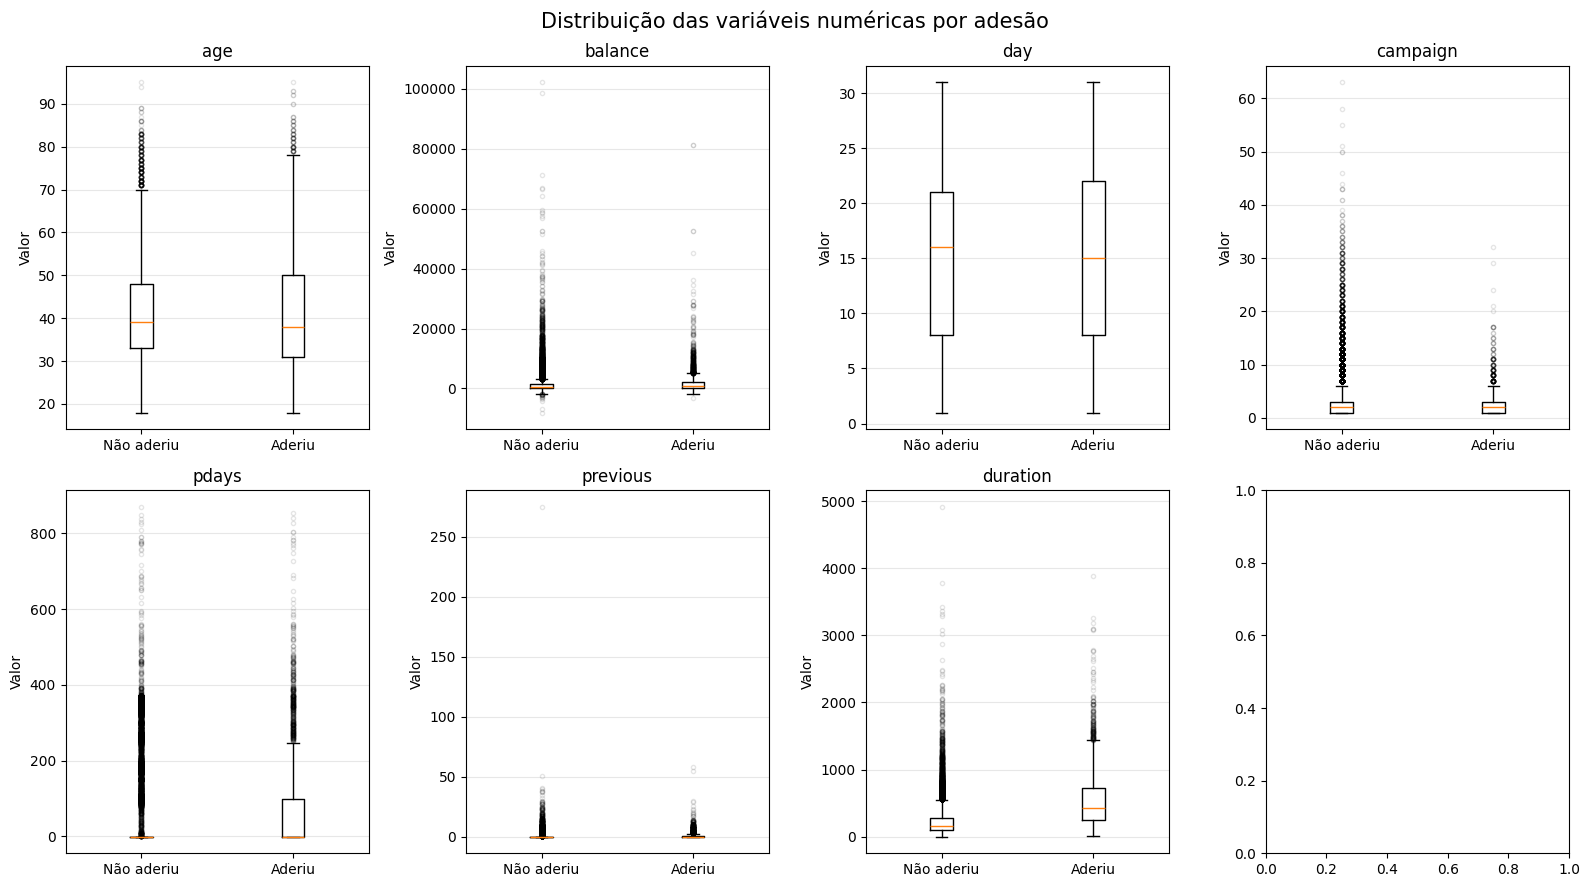

In [12]:
# Agora vamos usar boxplots para visualização gráfica, pois eles permitem comparar medianas, 
# dispersões e valores extremos entre os dois grupos. É uma boa primeira visualização para essa etapa.

import matplotlib.pyplot as plt

# Variáveis numéricas que serão comparadas.
numeric_cols = [
    "age", "balance", "day",
    "campaign", "pdays", "previous", "duration"
]

# Criar uma grade de gráficos com 2 linhas e 3 colunas
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

# Comparar a distribuição de cada variável entre os grupos
for col, ax in zip(numeric_cols, axes.flatten()):

    # Separar os valores de acordo com o resultado da campanha
    data = [
        df.loc[df["y"] == "no", col],
        df.loc[df["y"] == "yes", col]
    ]

    # Construir o boxplot.
    ax.boxplot(
        data,
        labels=["Não aderiu", "Aderiu"], # Em outras versões do matplotlib, esse parâmetro pode se chamar tick_labels
        showfliers=True, # Mostrar dados fora dos bigodes do gráfico
        flierprops=dict(
                            marker="o",
                            markersize=3,
                            alpha=0.1 # opacidade dos marcadores (o baixo valor facilita a identificação de zonas com maior densidade)
                        )
    )

    ax.set_title(col)
    ax.set_ylabel("Valor")
    ax.grid(axis="y", alpha=0.3)

# Ajustar o espaçamento entre os gráficos
plt.suptitle(
    "Distribuição das variáveis numéricas por adesão",
    fontsize=15
)

plt.tight_layout()
plt.show()


Observa-se a presença de valores extremos em todas as variáveis numéricas, exceto `day`, como esperado pela natureza dessa variável. Algumas distribuições apresentam concentrações expressivas de observações além dos limites dos boxplots, indicando assimetria e dispersão dos dados. Essas características serão consideradas na etapa de pré-processamento, especialmente na escolha das técnicas de escalonamento, evitando a remoção automática de observações que podem representar comportamentos legítimos dos clientes.

In [14]:
''' Variável durantion mantida'''
# A variável duration representa a duração da última ligação, em segundos.
# Como essa informação só está disponível após a realização do contato,
# ela não poderá ser utilizada em uma previsão feita antes da ligação.

# Porém, manteremos essa variável no presente estudo, pois queremos comparar os
# resultados com os da análise feita sem essa variável

' Variável durantion mantida'

In [15]:
# Último passo dessa etapa: transformar month em uma variável cíclica, já que todos os anos tem a mesma quantidade de meses
# além de o primeiro e o último acontecerem sempre em sequência.
import numpy as np

import numpy as np

# Preservação do mês original para estratificação posterior (spoiler: vamos considerar as proporções de meses e classes)
month_stratify = df['month'].copy()

# Codificação cíclica da variável month
month_mapping = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4,
    'may': 5, 'jun': 6, 'jul': 7, 'aug': 8,
    'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}

month_num = df['month'].map(month_mapping)

df['month_sin'] = np.sin(2 * np.pi * (month_num - 1) / 12)
df['month_cos'] = np.cos(2 * np.pi * (month_num - 1) / 12)

# Remoção da variável original
df.drop(columns='month', inplace=True)

# Verificação dos tipos das colunas
display(df.dtypes)
    
# não faremos o mesmo com day porque alguns meses tem 31 dias, outros 30 e fevereiro nem isso

age            int64
job           object
marital       object
education     object
default       object
balance        int64
housing       object
loan          object
contact       object
day            int64
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome      object
y             object
month_sin    float64
month_cos    float64
dtype: object

### Conclusão da Análise Exploratória Inicial

A análise exploratória permitiu identificar as principais características do conjunto de dados e orientar as próximas etapas do projeto. De modo geral, foram observados os seguintes aspectos:

- **Valores ausentes:** não foram identificados valores nulos (`NaN`). As categorias `unknown` encontradas em algumas variáveis categóricas foram analisadas, mas não foram encontradas evidências que justifiquem excluir dessas observações.
- **Valores extremos:** as variáveis numéricas apresentam valores fora dos limites identificados pelos boxplots, indicando distribuições assimétricas. Esses registros serão mantidos inicialmente, pois podem representar comportamentos legítimos dos clientes.
- **Variáveis categóricas:** foram observadas diferenças nas taxas de adesão entre algumas categorias, mas nenhuma evidência que justifique a exclusão de variáveis ou categorias nesta etapa.
- **Variável-alvo:** a distribuição apresenta desequilíbrio entre as classes, com aproximadamente 11,70% de adesões (`yes`), aspecto que será considerado na modelagem.
- **Variável duration:** será mantida para comparar este estudo com o anterior, feito sem essa variável.
- **Variável month:** Variável month: foi transformada por meio de codificação cíclica (seno e cosseno), preservando a relação de proximidade entre meses consecutivos, incluindo dezembro e janeiro. A variável original foi removida após a transformação.

Com isso, a análise exploratória inicial é considerada concluída. Na próxima etapa, será realizada a preparação dos dados e sua divisão em conjuntos de treinamento e teste, dando início ao desenvolvimento e à avaliação dos modelos de Machine Learning.

---

In [161]:
# Agora vamos para a preparação dos dados, divisão treino/teste e modelagem

In [16]:
# Separação entre atributos e variável-alvo

from sklearn.model_selection import train_test_split

# Separação dos atributos e da variável-alvo
X = df.drop(columns='y')
y = df['y']

# Vamos fazer uma estratificação conjunta por mês e variável-alvo
# O motivo é que a taxa de adesão varia bastante entre os meses. 
# Por exemplo, março apresentou aproximadamente 52% de adesão, enquanto maio apresentou apenas 6,72%.
# Portanto, vamos tentar garantir que esse comportamento aconteça em ambos os conjuntos
stratify_col = month_stratify.astype(str) + '_' + df['y']



### Divisão dos dados

# Os dados serão divididos em três conjuntos: 70% para treinamento e seleção do modelo, 
# 10% para validação e calibração do limiar de decisão (threshold) e 20% para teste final. 
# Essa proporção está dentro dos intervalos apresentados pelo material da disciplina CSC311, 
# da Universidade de Toronto (https://www.teach.cs.toronto.edu/~csc311notes/supervised_learning/supervised.html?utm_source=chatgpt.com)

# Primeira divisão: 80% do total original são destinados ao desenvolvimento
# e os 20% restantes são reservados para o teste final.
X_dev, X_test, y_dev, y_test, stratify_dev, stratify_test = train_test_split(
    X,
    y,
    stratify_col,
    test_size=0.2,
    stratify=stratify_col,
    random_state=0
)

# Segunda divisão: os 80% destinados ao desenvolvimento são subdivididos.
# 87,5% desses dados correspondem a 70% do total original (treinamento),
# enquanto os 12,5% restantes correspondem a 10% do total original (validação).
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.125,
    stratify=stratify_dev,
    random_state=0
)

print(f'Treinamento: {X_train.shape[0]} registros')
print(f'Validação: {X_val.shape[0]} registros')
print(f'Teste: {X_test.shape[0]} registros')

Treinamento: 31647 registros
Validação: 4521 registros
Teste: 9043 registros


In [17]:
# Verificação da distribuição das classes e meses
# Vamos confirmar se o balanceamento relativo foi preservado nos dois conjuntos

month_distribution = pd.DataFrame({
    'Conjunto completo': month_stratify.value_counts(normalize=True) * 100,
    'Treinamento': month_stratify.loc[X_train.index].value_counts(normalize=True) * 100,
    'Validação': month_stratify.loc[X_val.index].value_counts(normalize=True) * 100,
    'Teste': month_stratify.loc[X_test.index].value_counts(normalize=True) * 100
})

display(month_distribution.round(2))

,Conjunto completo,Treinamento,Validação,Teste
may,30.45,30.45,30.44,30.44
jul,15.25,15.25,15.26,15.25
aug,13.82,13.81,13.82,13.82
jun,11.81,11.81,11.81,11.81
nov,8.78,8.78,8.78,8.78
apr,6.49,6.49,6.48,6.48
feb,5.86,5.86,5.86,5.86
jan,3.10,3.11,3.10,3.10
oct,1.63,1.63,1.64,1.64
sep,1.28,1.28,1.28,1.28


In [164]:
# Ótimo. A distribuição mensal ficou praticamente idêntica nos quatro conjuntos.

In [18]:
# Agora vamos fazer com que as categóricas passem do tipo 'object' para o tipo 'category'.
# Isso porque vamos utilizar uma abordagem diferente no algoritmo XGBoost (enable_categorical=True), 
# que permite lidar com categoricas sem usar O.H.E.

# Converter as variáveis categóricas de object para category
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

for coluna in categorical_cols:
    X_train[coluna] = X_train[coluna].astype('category')

    categorias_treino = X_train[coluna].cat.categories

    X_val[coluna] = pd.Categorical(
        X_val[coluna],
        categories=categorias_treino
    )

    X_test[coluna] = pd.Categorical(
        X_test[coluna],
        categories=categorias_treino
    )

# Verificar os tipos das variáveis categóricas
display(X_train[categorical_cols].dtypes)
display(X_val[categorical_cols].dtypes)
display(X_test[categorical_cols].dtypes)

job          category
marital      category
education    category
default      category
housing      category
loan         category
contact      category
poutcome     category
dtype: object

job          category
marital      category
education    category
default      category
housing      category
loan         category
contact      category
poutcome     category
dtype: object

job          category
marital      category
education    category
default      category
housing      category
loan         category
contact      category
poutcome     category
dtype: object

In [19]:
# Agora vamos agrupar colunas por tipo para definir como cada uma será processada 
cyclic_cols = ['month_sin', 'month_cos']

numeric_cols = [
    col for col in X_train.select_dtypes(include='number').columns
    if col not in cyclic_cols
]

categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Cíclicas:", cyclic_cols)
print("Numéricas:", numeric_cols)
print("Categóricas:", categorical_cols)

Cíclicas: ['month_sin', 'month_cos']
Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']


In [20]:
# Aqui vamos criar um pré-processador
# As colunas numéricas serão processadas com RobustScaler, pois identificamos distribuições assimétricas 
# e valores extremos (outliers), para os quais o método é menos sensível do que o StandardScaler.
# E as categóricas serão processadas com One Hot Encoding (exceto no XGBoost)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
preprocessador = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('cyc', 'passthrough', cyclic_cols)
    ]
)

In [21]:
# aqui fizemos gridsearch e otimização de threshold ao mesmo tempo, mas só funciona pra xgboost

# Agora vamos definir os algoritmos que utilizaremos para o treinamento de modelos

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Como temos um desbalanceamento de classes, vamos usar class_weight='balanced' quando possível
# e fazer o equivalente com scale_pos_weight para o XGBoost
scale_pos_weight = (y_train == 'no').sum() / (y_train == 'yes').sum()  # (negativos)/(positivos)
# Lembrando que esse valor será calculado com os dados de treino para evitar usar informações do teste na configuração do modelo

modelos = {
    'Logistic Regression': Pipeline([
        ('preprocessador', preprocessador),
        ('modelo', LogisticRegression(
            class_weight='balanced',
            max_iter=1000, # Pra que o modelo consiga fazer um número razoável de iterações (o padrão é 100)
            random_state=0
        ))
    ]),

    'Decision Tree': Pipeline([
        ('preprocessador', preprocessador),
        ('modelo', DecisionTreeClassifier(
            class_weight='balanced',
            random_state=0
        ))
    ]),

    'Random Forest': Pipeline([
        ('preprocessador', preprocessador),
        ('modelo', RandomForestClassifier(
            class_weight='balanced',
            random_state=0
        ))
    ]),

    'XGBoost': XGBClassifier(
        enable_categorical=True, # habilita o tratamento nativo de variáveis categóricas (Sem O.H.E.)
        tree_method='hist', # método de construção das árvores compatível com esse recurso.
        scale_pos_weight=scale_pos_weight,  # (negativos)/(positivos)
        random_state=0
    )
}

In [22]:
# Hiperparâmetros que serão testados para o algoritmo que tiver melhor desempenho

hiperparametros = {
    'Logistic Regression': {
        'modelo__C': [0.1, 1, 10],
        'modelo__solver': ['lbfgs', 'newton-cg', 'saga']
    },

    'Decision Tree': {
        'modelo__criterion': ['gini', 'entropy'],
        'modelo__max_depth': [5, 10, 15, None],
        'modelo__min_samples_split': [2, 10],
        'modelo__min_samples_leaf': [1, 5]
    },

    'Random Forest': {
        'modelo__n_estimators': [100, 200],
        'modelo__max_depth': [10, 20, None],
        'modelo__min_samples_split': [2, 10],
        'modelo__min_samples_leaf': [1, 5]
    },

    'XGBoost': [
        {
            'grow_policy': ['depthwise'],
            'max_depth': [3, 6],
            'min_child_weight': [1, 5]
        },
        {
            'grow_policy': ['lossguide'],
            'max_depth': [0],
            'max_leaves': [15, 31],
            'min_child_weight': [1, 5]
        }
    ]
}

In [23]:
# Agora vamos definir as condições de treinamento com validação cruzada K-fold

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=0
)

y_train_bin = y_train.map({'no': 0, 'yes': 1}) # bin de binário

metricas = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

In [24]:
# Executar o treinamento

resultados = []

for nome, modelo in modelos.items():

    scores = cross_validate(
        modelo,
        X_train,
        y_train_bin,
        cv=cv,
        scoring=metricas,
        n_jobs=1,
        verbose=3 # Para printar o progresso
    )

    resultados.append({
        'Modelo': nome,
        'F1-Score': scores['test_f1'].mean(), # combina precisão e recall em um único valor, mas não substitui a análise individual dessas métricas
        'PR-AUC': scores['test_pr_auc'].mean(), # avalia o compromisso entre precisão e recall em diferentes limiares
        'ROC-AUC': scores['test_roc_auc'].mean(), # avaliar a capacidade geral de discriminação
        'Precisão': scores['test_precision'].mean(), # dos classificados pelo modelo como positivos, quantos realmente eram?
        'Recall': scores['test_recall'].mean(), # das amostras positivas, quantas ele conseguiu classificar como positivas?
    })

resultados_df = pd.DataFrame(resultados).set_index('Modelo')

display(resultados_df.sort_values('F1-Score', ascending=False).round(4))

[CV] END  f1: (test=0.528) pr_auc: (test=0.506) precision: (test=0.396) recall: (test=0.789) roc_auc: (test=0.892) total time=   6.0s
[CV] END  f1: (test=0.526) pr_auc: (test=0.529) precision: (test=0.388) recall: (test=0.817) roc_auc: (test=0.899) total time=   6.0s
[CV] END  f1: (test=0.524) pr_auc: (test=0.530) precision: (test=0.391) recall: (test=0.793) roc_auc: (test=0.895) total time=   5.3s
[CV] END  f1: (test=0.517) pr_auc: (test=0.513) precision: (test=0.384) recall: (test=0.791) roc_auc: (test=0.893) total time=   3.8s
[CV] END  f1: (test=0.451) pr_auc: (test=0.269) precision: (test=0.463) recall: (test=0.440) roc_auc: (test=0.686) total time=   0.7s
[CV] END  f1: (test=0.436) pr_auc: (test=0.257) precision: (test=0.444) recall: (test=0.428) roc_auc: (test=0.678) total time=   0.7s
[CV] END  f1: (test=0.473) pr_auc: (test=0.286) precision: (test=0.477) recall: (test=0.469) roc_auc: (test=0.700) total time=   0.7s
[CV] END  f1: (test=0.432) pr_auc: (test=0.255) precision: (te

,F1-Score,PR-AUC,ROC-AUC,Precisão,Recall
Modelo,,,,,
XGBoost,0.5993,0.5914,0.9227,0.4980,0.7526
Logistic Regression,0.5238,0.5195,0.8946,0.3900,0.7977
Decision Tree,0.4480,0.2668,0.6849,0.4582,0.4384
Random Forest,0.4170,0.5912,0.9265,0.6739,0.3025


In [26]:
# Aqui vamos utilizar as métricas do passo anterior pra montar um ranking híbrido
metricas = ['F1-Score', 'PR-AUC', 'ROC-AUC']

# Criar rankings individuais (1 = melhor desempenho)
rankings = resultados_df[metricas].rank(
    ascending=False,
    method='min'
)

# Calcular Reciprocal Rank Fusion (RRF)
k = 60

resultados_df['RRF'] = sum(
    1 / (k + rankings[coluna])
    for coluna in metricas
)

# Ordenar modelos pelo ranking híbrido
resultados_df = resultados_df.sort_values(
    by='RRF',
    ascending=False
)

display(resultados_df)

,F1-Score,PR-AUC,ROC-AUC,Precisão,Recall,RRF
Modelo,,,,,,
XGBoost,0.599341,0.591398,0.922714,0.498043,0.752559,0.048916
Random Forest,0.416951,0.591217,0.926532,0.673878,0.302530,0.048147
Logistic Regression,0.523826,0.519453,0.894620,0.390009,0.797673,0.047875
Decision Tree,0.448028,0.266791,0.684886,0.458176,0.438406,0.047123


In [27]:
# Aqui vamos selecionar automaticamente o modelo com maior pontuação no ranking híbrido
# e, em seguida, executar um GridSearch somente nele

# Selecionar o modelo com maior pontuação RRF na comparação inicial

melhor_nome = resultados_df['RRF'].idxmax()

melhor_modelo = modelos[melhor_nome]

# Recuperar as métricas originais do modelo selecionado
pr_auc_original = resultados_df.loc[melhor_nome, 'PR-AUC']
f1_original = resultados_df.loc[melhor_nome, 'F1-Score']
roc_auc_original = resultados_df.loc[melhor_nome, 'ROC-AUC']


# Recuperar os hiperparâmetros do modelo selecionado
hiperparametros_busca = hiperparametros[melhor_nome]

print(f"Melhor modelo: {melhor_nome}")
print(f"PR-AUC original: {pr_auc_original:.4f}")
print(f"ROC-AUC original: {roc_auc_original:.4f}")
print(f"F1-Score original: {f1_original:.4f}")
print(f"Pontuação RRF: {resultados_df.loc[melhor_nome, 'RRF']:.6f}")
print(f"Hiperparâmetros a serem testados: {hiperparametros_busca}")

Melhor modelo: XGBoost
PR-AUC original: 0.5914
ROC-AUC original: 0.9227
F1-Score original: 0.5993
Pontuação RRF: 0.048916
Hiperparâmetros a serem testados: [{'grow_policy': ['depthwise'], 'max_depth': [3, 6], 'min_child_weight': [1, 5]}, {'grow_policy': ['lossguide'], 'max_depth': [0], 'max_leaves': [15, 31], 'min_child_weight': [1, 5]}]


In [28]:
# Configurar e executar o GridSearch

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

metrica_escolha = input("Qual será o critério para escolher o melhor modelo? Digite 0 para average_precision (PR-AUC) ou qualquer outra coisa para F1 Score:")
if str(metrica_escolha) == "0":
    metrica_nome = "PR-AUC" # Nome a ser exibido em print
    gs_scoring = "average_precision" # parâmetro do GridSearch
    metrica_original = pr_auc_original # Recuperar valor na célula do rankeamento
else:
    metrica_nome = "F1-Score" # Nome a ser exibido em prints
    gs_scoring = "f1" # parâmetro do GridSearch
    metrica_original = f1_original  # Recuperar valor na célula do rankeamento
print(f"Procurando modelo com melhor {metrica_nome}...")

# Recuperar o modelo selecionado e seus hiperparâmetros correspondentes
pipeline = clone(melhor_modelo)

# Configurar e executar o GridSearch
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=hiperparametros_busca,
    scoring=gs_scoring, # Métrica de scoring definida na variável gs_scoring
    cv=cv,
    n_jobs=1,
    verbose=3
)

# Usar y_train_bin, pois a variável-alvo foi convertida para 0 e 1
grid_search.fit(X_train, y_train_bin)

print("----------------------------------------------------------------------------------------------------------------------------------")
print("Melhores hiperparâmetros encontrados:", grid_search.best_params_)
print(f"{metrica_nome} do Grid Search:", round(grid_search.best_score_, 4))
print("----------------------------------------------------------------------------------------------------------------------------------")

print("Comparando o modelo original com o melhor modelo do GridSearch...")

# Criar tabela comparando o F1-score original e o obtido após a otimização
comparacao_metrica = pd.DataFrame({
    str(metrica_nome): [ 
        f"{metrica_original:.4f}",
        f"{grid_search.best_score_:.4f}",
        f"{grid_search.best_score_ - metrica_original:+.4f}" # esse "+"" em "+.4f" faz aparecer o sinal positivo antes do número se houver melhora
    ]
}, index=['Original', 'Grid Search', 'Diferença'])

display(comparacao_metrica.round(4))
#-----------------------------------------------------------------------------------------------------------------------------------------

# Manter a melhor configuração entre o modelo original e o otimizado
if grid_search.best_score_ > metrica_original:
    melhor_modelo = grid_search.best_estimator_
    melhor_metrica = grid_search.best_score_
    print("Modelo otimizado pelo Grid Search selecionado.")
else:
    # Recuperar o modelo original e treiná-lo com todos os dados de treinamento
    melhor_modelo = clone(modelos[melhor_nome]).fit(X_train, y_train_bin)
    melhor_metrica = metrica_original
    print("Modelo original mantido.")
print("----------------------------------------------------------------------------------------------------------------------------------")

# Preparar a visualização dos hiperparâmetros do melhor modelo

# Se for XGBoost, os parâmetros estãro diretamente no estimador.
# Nos demais modelos, estarão dentro da etapa 'modelo' do Pipeline.
if melhor_nome == "XGBoost":
    modelo_final = melhor_modelo
else:
    modelo_final = melhor_modelo.named_steps["modelo"]

padrao = modelo_final.__class__().get_params(deep=False)  # Selecionar os hiperparâmetros padrão para NÃO MOSTRAR
modificados = [
    f"{k}={v}"
    for k, v in modelo_final.get_params(deep=False).items()
    if v != padrao.get(k)
]  # Comparar e mostrar somente os diferentes

modelo_hiperametros_texto = f"{modelo_final.__class__.__name__}({', '.join(modificados)})"  # Salvar o texto legível nessa variável

print("Melhor modelo até agora:", modelo_hiperametros_texto)
print(f"{metrica_nome} do modelo selecionado:", round(melhor_metrica, 4))

Procurando modelo com melhor PR-AUC...
Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV 1/4] END grow_policy=depthwise, max_depth=3, min_child_weight=1;, score=0.594 total time=   0.9s
[CV 2/4] END grow_policy=depthwise, max_depth=3, min_child_weight=1;, score=0.604 total time=   0.5s
[CV 3/4] END grow_policy=depthwise, max_depth=3, min_child_weight=1;, score=0.624 total time=   0.5s
[CV 4/4] END grow_policy=depthwise, max_depth=3, min_child_weight=1;, score=0.601 total time=   0.6s
[CV 1/4] END grow_policy=depthwise, max_depth=3, min_child_weight=5;, score=0.590 total time=   0.5s
[CV 2/4] END grow_policy=depthwise, max_depth=3, min_child_weight=5;, score=0.611 total time=   0.5s
[CV 3/4] END grow_policy=depthwise, max_depth=3, min_child_weight=5;, score=0.619 total time=   0.5s
[CV 4/4] END grow_policy=depthwise, max_depth=3, min_child_weight=5;, score=0.615 total time=   0.5s
[CV 1/4] END grow_policy=depthwise, max_depth=6, min_child_weight=1;, score=0.582 total time=

,PR-AUC
Original,0.5914
Grid Search,0.6086
Diferença,+0.0172


Modelo otimizado pelo Grid Search selecionado.
----------------------------------------------------------------------------------------------------------------------------------
Melhor modelo até agora: XGBClassifier(enable_categorical=True, grow_policy=depthwise, max_depth=3, min_child_weight=5, missing=nan, random_state=0, scale_pos_weight=7.548622366288493, tree_method=hist)
PR-AUC do modelo selecionado: 0.6086


### Otimização e seleção do threshold

Agora serão avaliadas três estratégias de classificação utilizando o conjunto de validação (10% dos dados):

- **Threshold padrão:** valor de 0.5, utilizado como referência.
- **Otimização por F1-score:** seleção do threshold que maximiza o F1-score.
- **Otimização pelo índice de Youden:** seleção do threshold que maximiza a diferença entre a taxa de verdadeiros positivos (TPR) e a taxa de falsos positivos (FPR).

As estratégias otimizadas serão comparadas individualmente com o threshold padrão, considerando os seguintes critérios:

1. **Melhora relativa do F1-score:** deve ser igual ou superior a 5%.
2. **Aumento relativo da FPR:** deve ser igual ou inferior a 10%.
3. **Redução relativa do Recall (TPR):** deve ser igual ou inferior a 25%.

Uma estratégia otimizada será considerada aceitável somente se atender simultaneamente aos três critérios. Caso uma ou ambas sejam aceitas, será selecionada aquela que apresentar o maior F1-score. Se nenhuma atender aos critérios, será mantido o threshold padrão de 0.5.

A seleção será realizada exclusivamente com os dados de validação. O conjunto de teste (20%) permanecerá reservado para a avaliação final do modelo, sem interferir na escolha do threshold.

In [37]:
# Otimização e comparação dos thresholds utilizando o conjunto de validação

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Garantir que o modelo esteja treinado (evitar NotFittedError)
melhor_modelo.fit(X_train, y_train_bin)

# Passar os rotulos do conjunto de validação pro formato binário
y_val_bin = y_val.map({'no': 0, 'yes': 1}) # bin de binário

# Obter as probabilidades de pertencimento à classe positiva
probabilidades_val = melhor_modelo.predict_proba(X_val)[:, 1]
# Obter os valores de ROC e AUC do melhor modelo
pr_auc_val = average_precision_score(y_val_bin, probabilidades_val)
roc_auc_val = roc_auc_score(y_val_bin, probabilidades_val)

# Calcular as métricas para diferentes thresholds
precisoes, recalls, thresholds_f1 = precision_recall_curve(
    y_val_bin,
    probabilidades_val
)

# Calcular o F1-score para cada threshold
f1_scores = (
    2 * precisoes[:-1] * recalls[:-1] /
    (precisoes[:-1] + recalls[:-1] + 1e-10)
)

# Selecionar o threshold que maximiza o F1-score
indice_f1 = np.argmax(f1_scores)
threshold_f1 = thresholds_f1[indice_f1]

# Calcular o índice de Youden para diferentes thresholds
fprs, tprs, thresholds_youden = roc_curve(
    y_val_bin,
    probabilidades_val
)

youden_scores = tprs - fprs

# Selecionar o threshold que maximiza o índice de Youden
indice_youden = np.argmax(youden_scores)
threshold_youden = thresholds_youden[indice_youden]


# Definir os thresholds que serão comparados
thresholds = {
    'Padrão (0.5)': 0.5,
    'Otimizado por F1': threshold_f1,
    'Otimizado por Youden': threshold_youden
}

# Calcular as métricas para cada estratégia
resultados = []

for estrategia, threshold in thresholds.items():

    # Gerar as classificações com o threshold atual
    y_pred = (probabilidades_val >= threshold).astype(int)

    # Obter os valores da matriz de confusão
    tn, fp, fn, tp = confusion_matrix(
        y_val_bin,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Calcular as métricas
    resultados.append({
        'Estratégia': estrategia,
        'Threshold': threshold,
        'F1-score': f1_score(y_val_bin, y_pred, zero_division=0),
        'Acurácia': accuracy_score(y_val_bin, y_pred),
        'Precisão': precision_score(y_val_bin, y_pred, zero_division=0),
        'Recall (TPR)': recall_score(y_val_bin, y_pred, zero_division=0),
        'FPR': fp / (fp + tn)
    })

# Organizar os resultados em uma tabela
resultados_threshold = pd.DataFrame(resultados).set_index('Estratégia')

# Ordenar pelo F1-score em ordem decrescente
resultados_threshold = resultados_threshold.sort_values(
    by='Threshold',
    ascending=True
)

print(f"PR-AUC do melhor modelo: {pr_auc_val:.4}")
print(f"ROC-AUC do melhor modelo: {roc_auc_val:.4}")
print("Lembrando que essas métricas não mudam com a variação do threshold.")
display(resultados_threshold.round(4))

#-----------------------------------------------------------------------------------------------------------------------------------------

# Comparar individualmente as estratégias otimizadas com o threshold padrão

padrao = resultados_threshold.loc['Padrão (0.5)']

estrategias_aceitas = []

for estrategia in ['Otimizado por F1', 'Otimizado por Youden']:

    resultado = resultados_threshold.loc[estrategia]

    # Calcular as variações relativas em relação ao threshold padrão
    melhora_f1 = (
        (resultado['F1-score'] - padrao['F1-score'])
        / padrao['F1-score']
    )

    aumento_fpr = (
        (resultado['FPR'] - padrao['FPR'])
        / padrao['FPR']
    )

    reducao_recall = (
        (padrao['Recall (TPR)'] - resultado['Recall (TPR)'])
        / padrao['Recall (TPR)']
    )

    # Verificar se a estratégia atende aos três critérios
    aceita = (
        melhora_f1 >= 0.05 and
        aumento_fpr <= 0.10 and
        reducao_recall <= 0.25
    )

    print(f"\n{estrategia}:")
    print(f"Variação do F1-score em relação ao padrão: {melhora_f1:+.2%}")
    print(f"Variação da FPR em relação ao padrão: {aumento_fpr:+.2%}")
    print(f"Variação do Recall em relação ao padrão: {reducao_recall:+.2%}")
    print("Critérios atendidos:", "Sim" if aceita else "Não")

    if aceita:
        estrategias_aceitas.append(estrategia)

# Selecionar o threshold final
if estrategias_aceitas:

    estrategia_selecionada = resultados_threshold.loc[
        estrategias_aceitas, 'F1-score'
    ].idxmax()

else:
    estrategia_selecionada = 'Padrão (0.5)'

threshold_selecionado = resultados_threshold.loc[
    estrategia_selecionada, 'Threshold'
]

print("\n" + "-" * 70)
print("Estratégia selecionada:", estrategia_selecionada)
print("Threshold selecionado:", round(threshold_selecionado, 4))
print("-" * 70)

PR-AUC do melhor modelo: 0.6191
ROC-AUC do melhor modelo: 0.9294
Lembrando que essas métricas não mudam com a variação do threshold.


,Threshold,F1-score,Acurácia,Precisão,Recall (TPR),FPR
Estratégia,,,,,,
Otimizado por Youden,0.3308,0.5249,0.8034,0.3659,0.9282,0.2132
Padrão (0.5),0.5000,0.5712,0.8483,0.4267,0.8639,0.1538
Otimizado por F1,0.7637,0.6298,0.9038,0.5728,0.6994,0.0691



Otimizado por F1:
Variação do F1-score em relação ao padrão: +10.25%
Variação da FPR em relação ao padrão: -55.05%
Variação do Recall em relação ao padrão: +19.04%
Critérios atendidos: Sim

Otimizado por Youden:
Variação do F1-score em relação ao padrão: -8.12%
Variação da FPR em relação ao padrão: +38.60%
Variação do Recall em relação ao padrão: -7.44%
Critérios atendidos: Não

----------------------------------------------------------------------
Estratégia selecionada: Otimizado por F1
Threshold selecionado: 0.7637
----------------------------------------------------------------------


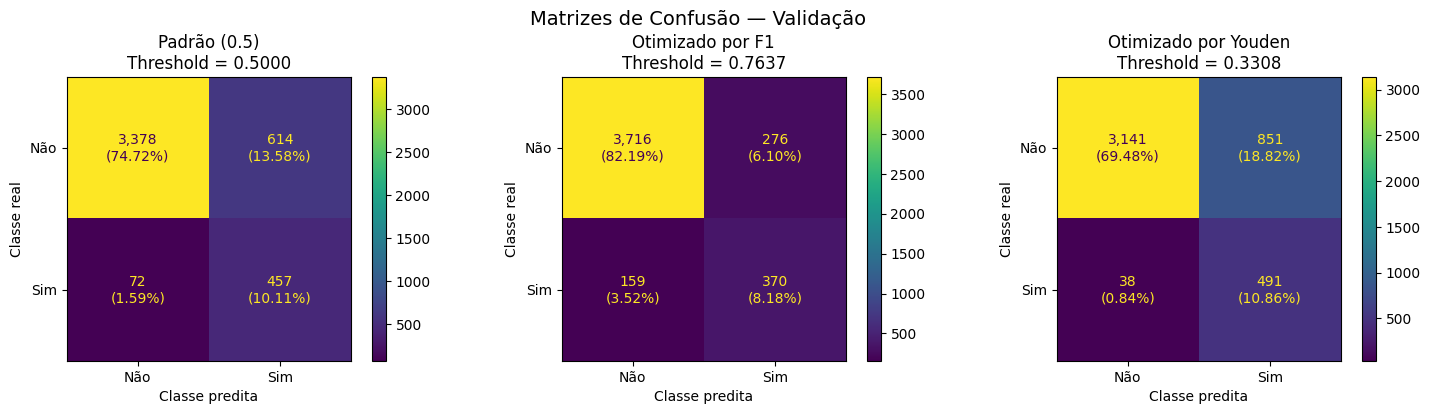

In [38]:
# Matrizes de confusão

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, estrategia in zip(axes, thresholds.keys()):

    threshold = thresholds[estrategia]

    y_pred = (probabilidades_val >= threshold).astype(int)

    matriz = confusion_matrix(
        y_val_bin,
        y_pred,
        labels=[0, 1]
    )

    # Calcular as porcentagens em relação ao total de observações
    matriz_percentual = matriz / matriz.sum() * 100

    # Formatar os valores como absoluto (porcentagem)
    anotacoes = np.array([
        [
            f'{matriz[i, j]:,}\n({matriz_percentual[i, j]:.2f}%)'
            for j in range(2)
        ]
        for i in range(2)
    ])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=['Não', 'Sim']
    )

    disp.plot(
        ax=ax,
        colorbar=True,
        values_format='d'
    )

    # Substituir as anotações padrão pelas personalizadas
    for texto, anotacao in zip(disp.text_.ravel(), anotacoes.ravel()):
        texto.set_text(anotacao)

    ax.set_title(f'{estrategia}\nThreshold = {threshold:.4f}')
    ax.set_xlabel('Classe predita')
    ax.set_ylabel('Classe real')

plt.suptitle('Matrizes de Confusão — Validação', fontsize=14)
plt.tight_layout()
plt.show()

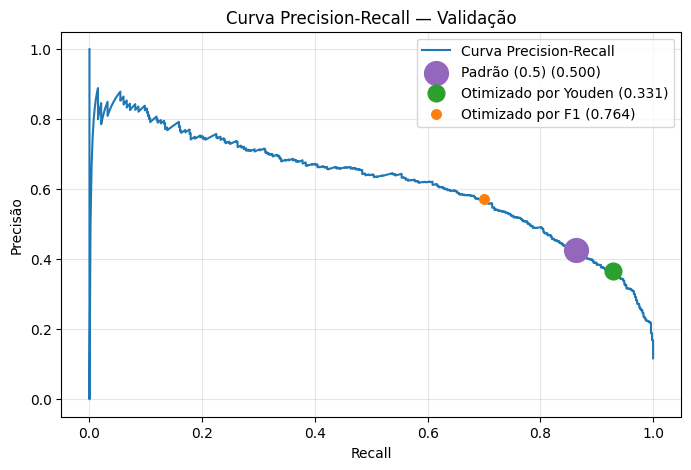

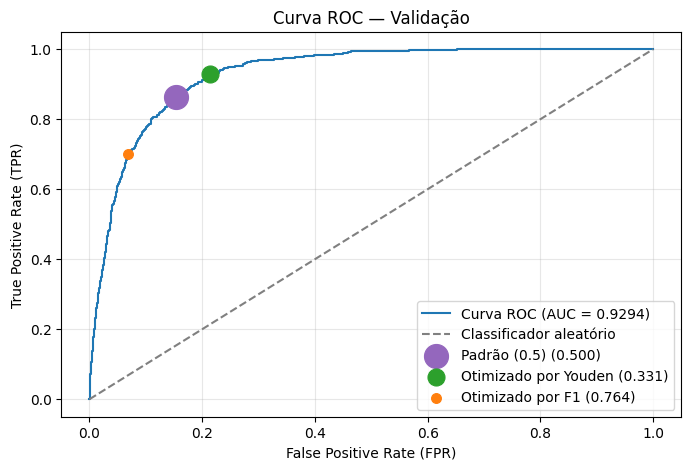

In [39]:
# Traçar curvas ROC e PR

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

# Calcular os pontos das curvas
precisoes, recalls, _ = precision_recall_curve(
    y_val_bin,
    probabilidades_val
)

fprs, tprs, _ = roc_curve(
    y_val_bin,
    probabilidades_val
)

auc_roc = roc_auc_score(y_val_bin, probabilidades_val)

# Definir cores e tamanhos dos marcadores
cores = {
    'Padrão (0.5)': 'tab:purple',
    'Otimizado por F1': 'tab:orange',
    'Otimizado por Youden': 'tab:green'
}

tamanhos = { # Tamanhos diferentes pra evitar que pontos muito próximos se sobreponham
    'Padrão (0.5)': 300,
    'Otimizado por Youden': 150,
    'Otimizado por F1': 50
}

# Ordem de desenho: maior para menor
ordem_graficos = [
    'Padrão (0.5)',
    'Otimizado por Youden',
    'Otimizado por F1'
]

#-----------------------------------------------------------------------------------------------------------------------------------------
# Gráfico Precision-Recall

plt.figure(figsize=(8, 5))

plt.plot(
    recalls,
    precisoes,
    label='Curva Precision-Recall'
)

for estrategia in ordem_graficos:

    threshold = thresholds[estrategia]

    y_pred = (probabilidades_val >= threshold).astype(int)

    precisao = precision_score(y_val_bin, y_pred, zero_division=0)
    recall = recall_score(y_val_bin, y_pred, zero_division=0)

    plt.scatter(
        recall,
        precisao,
        s=tamanhos[estrategia],
        color=cores[estrategia],
        # edgecolors='black',
        linewidths=0.8,
        label=f'{estrategia} ({threshold:.3f})',
        zorder=3
    )

plt.xlabel('Recall')
plt.ylabel('Precisão')
plt.title('Curva Precision-Recall — Validação')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#-----------------------------------------------------------------------------------------------------------------------------------------
# Gráfico ROC

plt.figure(figsize=(8, 5))

plt.plot(
    fprs,
    tprs,
    label=f'Curva ROC (AUC = {auc_roc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Classificador aleatório',
    color='gray'
)

for estrategia in ordem_graficos:

    threshold = thresholds[estrategia]

    y_pred = (probabilidades_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_bin,
        y_pred,
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)
    tpr = tp / (tp + fn)

    plt.scatter(
        fpr,
        tpr,
        s=tamanhos[estrategia],
        color=cores[estrategia],
        # edgecolors='black',
        linewidths=0.8,
        label=f'{estrategia} ({threshold:.3f})',
        zorder=3
    )

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC — Validação')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Fase de testes

Resultados da fase de testes:



,Valor
Acurácia,0.8967
Precisão,0.5456
Recall (TPR),0.7013
F1-score,0.6137
FPR,0.0774
ROC-AUC,0.9334
PR-AUC,0.6310


Threshold utilizado: 0.7637

Matriz de Confusão

                       Predito
                     Não          Sim
Real    Não   7,367 (81.47%)   618 (6.83%)
Real    Sim     316 (3.49%)    742 (8.21%)


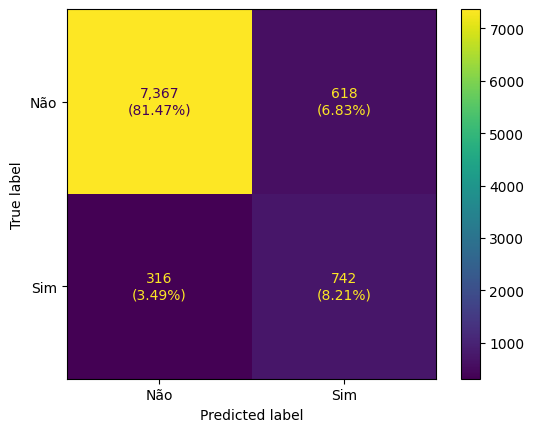

In [41]:
# Agora é a avaliação final. Vamos utilizar o modelo treinado nos 70% e o threshold selecionado na validação (0.6483), sem fazer nenhum ajuste adicional.

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Converter a variável-alvo do teste para valores binários
y_test_bin = y_test.map({'no': 0, 'yes': 1})

# Obter as probabilidades de pertencimento à classe positiva
probabilidades_test = melhor_modelo.predict_proba(X_test)[:, 1]

# Gerar as classificações utilizando o threshold selecionado na validação
y_pred_test = (probabilidades_test >= threshold_selecionado).astype(int)

#-----------------------------------------------------------------------------------------------------------------------------------------
# Calcular as métricas de avaliação

tn, fp, fn, tp = confusion_matrix(
    y_test_bin,
    y_pred_test,
    labels=[0, 1]
).ravel()

acuracia_test = accuracy_score(y_test_bin, y_pred_test)
precisao_test = precision_score(y_test_bin, y_pred_test, zero_division=0)
recall_test = recall_score(y_test_bin, y_pred_test, zero_division=0)
f1_test = f1_score(y_test_bin, y_pred_test, zero_division=0)
fpr_test = fp / (fp + tn)

auc_roc_test = roc_auc_score(y_test_bin, probabilidades_test)
auc_pr_test = average_precision_score(y_test_bin, probabilidades_test)

# Exibir os resultados
metricas_test = pd.DataFrame({
    'Valor': [
        acuracia_test,
        precisao_test,
        recall_test,
        f1_test,
        fpr_test,
        auc_roc_test,
        auc_pr_test
    ]
}, index=[
    'Acurácia',
    'Precisão',
    'Recall (TPR)',
    'F1-score',
    'FPR',
    'ROC-AUC',
    'PR-AUC'
])

print("Resultados da fase de testes:\n")
display(metricas_test.round(4))

print("Threshold utilizado:", round(threshold_selecionado, 4))

#-----------------------------------------------------------------------------------------------------------------------------------------
# Exibir a matriz de confusão

matriz = confusion_matrix(
    y_test_bin,
    y_pred_test,
    labels=[0, 1]
)

matriz_percentual = matriz / matriz.sum() * 100

anotacoes = np.array([
    [
        f'{matriz[i, j]:,}\n({matriz_percentual[i, j]:.2f}%)'
        for j in range(2)
    ]
    for i in range(2)
])

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Não', 'Sim']
)

disp.plot(
    colorbar=True,
    values_format='d'
)

for texto, anotacao in zip(disp.text_.ravel(), anotacoes.ravel()):
    texto.set_text(anotacao)

# Printar a matriz
matriz = confusion_matrix(y_test_bin, y_pred_test, labels=[0, 1])
matriz_percentual = matriz / matriz.sum() * 100

print("\nMatriz de Confusão")
print("\n                       Predito")
print("                     Não          Sim")
print(f"Real    Não   {matriz[0, 0]:,} ({matriz_percentual[0, 0]:.2f}%)   {matriz[0, 1]:,} ({matriz_percentual[0, 1]:.2f}%)")
print(f"Real    Sim     {matriz[1, 0]:,} ({matriz_percentual[1, 0]:.2f}%)    {matriz[1, 1]:,} ({matriz_percentual[1, 1]:.2f}%)")

In [42]:
#-----------------------------------------------------------------------------------------------------------------------------------------
# Conclusões da avaliação final

from IPython.display import display, Markdown

prevalencia_test = y_test_bin.mean() # Porcentagem correspondente à classe 1

display(Markdown(f"""
### O que os resultados do teste dizem?

- **F1-score = {f1_test:.4f}:** {"o modelo apresenta um equilíbrio elevado entre precisão e Recall." if f1_test >= 0.8 else "o modelo apresenta um bom equilíbrio entre precisão e Recall." if f1_test >= 0.6 else "o modelo apresenta um equilíbrio intermediário entre precisão e Recall." if f1_test >= 0.4 else "o modelo apresenta um equilíbrio limitado entre precisão e Recall."}
- **Precisão = {precisao_test:.2%}:** {"mais da metade" if precisao_test > 0.5 else "menos da metade" if precisao_test < 0.5 else "exatamente metade"} das previsões positivas corresponde a adesões reais.
- **Recall = {recall_test:.2%}:** o modelo identificou aproximadamente {recall_test:.1%} das adesões reais.
- **FPR = {fpr_test:.2%}:** aproximadamente {fpr_test:.1%} dos clientes que não aderiram foram classificados incorretamente como positivos.
- **ROC-AUC = {auc_roc_test:.4f}:** {"excelente" if auc_roc_test >= 0.9 else "boa" if auc_roc_test >= 0.8 else "razoável" if auc_roc_test >= 0.7 else "limitada" if auc_roc_test >= 0.6 else "baixa"} capacidade de distinguir clientes que aderiram daqueles que não aderiram, considerando diferentes thresholds.
- **PR-AUC = {auc_pr_test:.4f}:** {"superior" if auc_pr_test > prevalencia_test else "igual" if auc_pr_test == prevalencia_test else "inferior"} à prevalência da classe positiva ({prevalencia_test:.2%}), indicando um desempenho {"superior" if auc_pr_test > prevalencia_test else "equivalente" if auc_pr_test == prevalencia_test else "inferior"} ao de uma referência sem capacidade de discriminação.

"""))


### O que os resultados do teste dizem?

- **F1-score = 0.6137:** o modelo apresenta um bom equilíbrio entre precisão e Recall.
- **Precisão = 54.56%:** mais da metade das previsões positivas corresponde a adesões reais.
- **Recall = 70.13%:** o modelo identificou aproximadamente 70.1% das adesões reais.
- **FPR = 7.74%:** aproximadamente 7.7% dos clientes que não aderiram foram classificados incorretamente como positivos.
- **ROC-AUC = 0.9334:** excelente capacidade de distinguir clientes que aderiram daqueles que não aderiram, considerando diferentes thresholds.
- **PR-AUC = 0.6310:** superior à prevalência da classe positiva (11.70%), indicando um desempenho superior ao de uma referência sem capacidade de discriminação.



---
### Conclusão

Assim como no estudo feito sem a coluna `duration` XGBoost novamente apresentou o melhor desempenho geral entre os algoritmos avaliados. Após a otimização dos hiperparâmetros e a calibração do threshold, o modelo alcançou F1-score de 0,6137, precisão de 54,56% e Recall de 70,13% na avaliação final, além de ROC-AUC de 0,9334 e PR-AUC de 0,6310.

Na perspectiva de negócio, os resultados também foram expressivos: entre os clientes classificados como positivos, 54,56% realmente aderiram ao depósito, aproximadamente 4,66 vezes a prevalência original de 11,7%. Dos 1.058 clientes que efetivamente aderiram, 742 foram identificados corretamente.

A inclusão da variável `duration` proporcionou uma melhora significativa na capacidade preditiva do modelo, permitindo identificar 192 adesões adicionais em comparação ao experimento sem essa variável, além de reduzir o número de falsos positivos em 52.

Esse experimento evidencia o impacto que a disponibilidade de informações adicionais pode exercer sobre o desempenho de modelos de classificação. Entretanto, como `duration` somente é conhecida durante ou após a ligação, esse cenário representa uma análise complementar, enquanto o experimento sem essa variável permanece mais adequado à priorização de clientes antes do contato.